In [28]:
!mamba install pandas

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, pingouin
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 1.708 seconds
All requested packages already installed.


In [4]:
!mamba install pingouin

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, pingouin
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 1.219 seconds
  Name                Version     Build                Channel
----------------------------------------------------------------------------
+ brotli-python       1.2.0       py313h8faef1e_3      emscripten-forge-4x
+ ca-certificates     2026.10.23  hbd8a1cb_0           conda-forge
+ certifi             2026.10.23  pyhd8ed1ab_3         conda-forge
+ charset-normalizer  3.5.1       pyhd8ed1ab_0         conda-forge
+ idna                3.20        pyh5ded981_0         conda-forge
+ joblib              1.6.0       py313h57e9779_0      emscripten-forge-4x
+ littleutils         0.2.4       pyhd8ed1ab_1         conda-forge
+ mpmath              1.4.1       pyhd8ed1ab_0         conda-forge
+ narwhals            2.28.0      pyh5ded981_0         conda-forge
+ outdated            0.2.2  

In [29]:
import pandas as pd, pingouin as pg
nhanes=pd.read_csv("https://raw.githubusercontent.com/Psyc3000A/Data/refs/heads/main/nhanes.csv")
pg.chi2_independence(nhanes, x="HowOftenDoYouFeelDepressed", y="EverToldDoctorHadTroubleSleeping")

/tmp/xpython_42/3090870859.py:2: DtypeWarning: Columns (141: ServedActiveDutyInUsArmedForces) have mixed types. Specify dtype option on import or set low_memory=False.
  nhanes=pd.read_csv("https://raw.githubusercontent.com/Psyc3000A/Data/refs/heads/main/nhanes.csv")


(EverToldDoctorHadTroubleSleeping          0.0         1.0
 HowOftenDoYouFeelDepressed                               
 0.0                               1866.324319  706.675681
 1.0                               1251.953274  474.046726
 2.0                                322.780537  122.219463
 3.0                                282.160964  106.839036
 4.0                                219.780905   83.219095,
 EverToldDoctorHadTroubleSleeping   0.0  1.0
 HowOftenDoYouFeelDepressed                 
 0.0                               2137  436
 1.0                               1236  490
 2.0                                264  181
 3.0                                199  190
 4.0                                107  196,
                  test    lambda        chi2  dof           pval    cramer  \
 0             pearson  1.000000  482.605128  4.0  3.872451e-103  0.297959   
 1        cressie-read  0.666667  470.001830  4.0  2.057373e-100  0.294042   
 2      log-likelihood  0.000000  45

In [6]:

#pip install -qq pandas matplotlib scipy
import matplotlib.pylab as plt
# this is for test 1
print ("Hello World")

Hello World


In [8]:
children = nhanes[nhanes["AgeInYearsAtScreening"] < 18]

<Axes: >

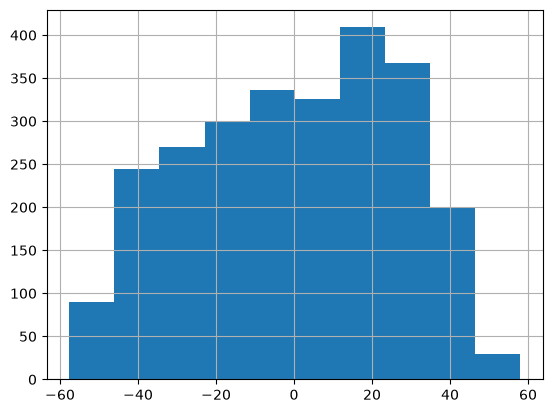

In [9]:
(children["StandingHeightCm"] - children["StandingHeightCm"].mean()).hist() #question 2 A

<Axes: >

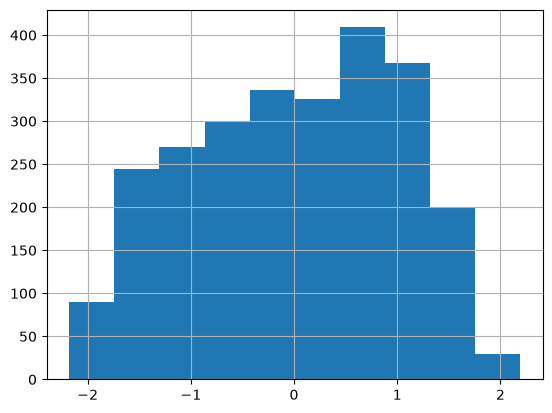

In [10]:
((children["StandingHeightCm"] - children["StandingHeightCm"].mean())/children["StandingHeightCm"].std()).hist() #question 2 A

array([[<Axes: title={'center': 'StandingHeightCm'}>,
        <Axes: title={'center': 'AgeInYearsAtScreening'}>]], dtype=object)

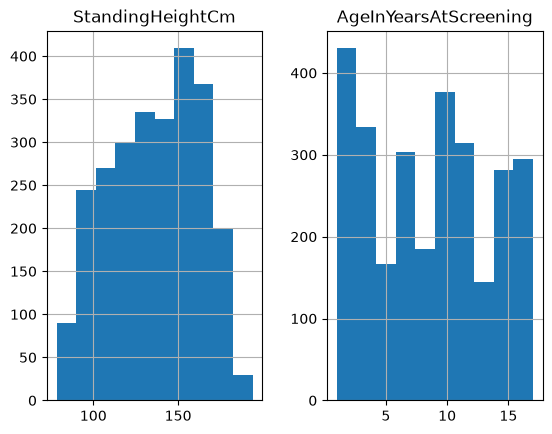

In [11]:
children[["StandingHeightCm","AgeInYearsAtScreening"]].hist() #Question 2 B

array([[<Axes: title={'center': 'StandingHeightCm'}>,
        <Axes: title={'center': 'AgeInYearsAtScreening'}>]], dtype=object)

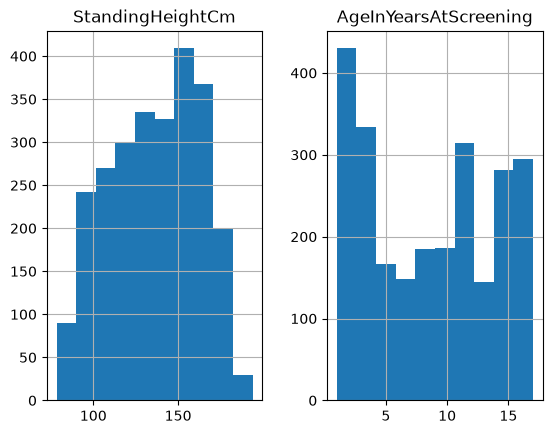

In [12]:
children[["StandingHeightCm","AgeInYearsAtScreening"]].replace([7,9,77,99,777,999,7777,9999], pd.NA).astype("Float64").hist() #question 2 B

In [13]:
children["AgeInYearsAtScreening"].describe() #question 2 C

count    2833.000000
mean        8.513590
std         4.905092
min         1.000000
25%         4.000000
50%         8.000000
75%        13.000000
max        17.000000
Name: AgeInYearsAtScreening, dtype: float64

In [14]:
children["AgeInYearsAtScreening"].dropna().describe() #question 2 C

count    2833.000000
mean        8.513590
std         4.905092
min         1.000000
25%         4.000000
50%         8.000000
75%        13.000000
max        17.000000
Name: AgeInYearsAtScreening, dtype: float64

<Axes: xlabel='StandingHeightCm', ylabel='BodyMassIndexKgm2'>

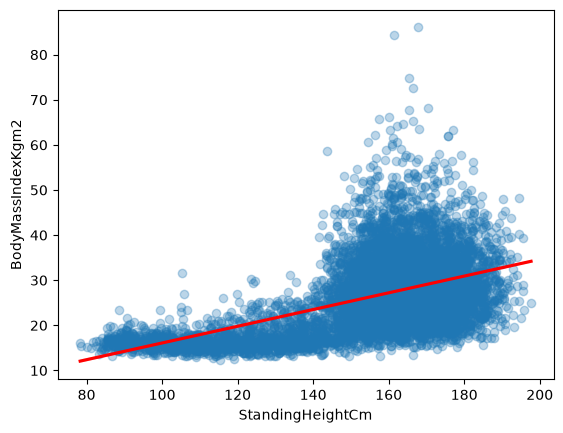

In [16]:
import seaborn as sns
import pingouin as pg
pg.linear_regression(nhanes["StandingHeightCm"], nhanes["BodyMassIndexKgm2"],remove_na=True)
sns.regplot(data=nhanes,x="StandingHeightCm", y="BodyMassIndexKgm2",scatter_kws={"color": "C0", "alpha": 0.3},line_kws={"color": "red"}) #question 2 D with the line

In [17]:
import seaborn as sns
import pingouin as pg
pg.linear_regression(nhanes["StandingHeightCm"], nhanes["BodyMassIndexKgm2"],remove_na=True) 
# question 2 D, running the line of code without the one below in instructions

,names,coef,se,T,pval,r2,adj_r2,CI2.5,CI97.5
0,Intercept,-2.443957,0.568574,-4.298396,0.000017,0.249317,0.249223,-3.558511,-1.329404
1,StandingHeightCm,0.185338,0.003595,51.555402,0.000000,0.249317,0.249223,0.178291,0.192385


In [31]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

children["Gender_code"] = (children["Gender"].astype(str).str.lower().isin(["male", "1"])).astype(int)
children  = children[["StandingHeightCm", "AgeInYearsAtScreening", "Gender_code"]].dropna()

m_age = LinearRegression(fit_intercept=False).fit(children[["AgeInYearsAtScreening"]],children["StandingHeightCm"])
m_age_const = LinearRegression().fit(children[["AgeInYearsAtScreening"]], children["StandingHeightCm"])

m_full = LinearRegression().fit(children[["AgeInYearsAtScreening", "Gender_code"]],children["StandingHeightCm"])
children = children.sort_values("AgeInYearsAtScreening")

children["pred_age"] = m_age.predict(children[["AgeInYearsAtScreening"]])
children["pred_age_const"] = m_age_const.predict(children[["AgeInYearsAtScreening"]])
children["pred_full"] = m_full.predict(children[["AgeInYearsAtScreening", "Gender_code"]])

children["Age_Gender"] = (children["AgeInYearsAtScreening"] * children["Gender_code"])

m_interaction = LinearRegression().fit(children[["AgeInYearsAtScreening","Gender_code","Age_Gender"]],children["StandingHeightCm"])

children["pred_interaction"] = m_interaction.predict(children[["AgeInYearsAtScreening","Gender_code","Age_Gender"]])
fig, ax = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)

# A: Original data
ax[0,0].scatter(children["AgeInYearsAtScreening"], children["StandingHeightCm"], alpha=.2)
ax[0,0].set_title("A. Original data")

# B: Age only
ax[0,1].scatter(children["AgeInYearsAtScreening"], children["StandingHeightCm"], alpha=.15)
ax[0,1].plot(children["AgeInYearsAtScreening"], children["pred_age"], color="red", lw=3)
ax[0,1].set_title("B. Age")

# C: Age + constant
ax[1,0].scatter(children["AgeInYearsAtScreening"], children["StandingHeightCm"], alpha=.15)
ax[1,0].plot(children["AgeInYearsAtScreening"], children["pred_age_const"], color="red", lw=3)
ax[1,0].set_title("C. Age + constant")

# D: Age + constant + gender
for g, color, label in [(0, "red", "Female"),(1, "green", "Male")]:
    tmp = children[children["Gender_code"] == g].sort_values("AgeInYearsAtScreening")
    ax[1,1].scatter(tmp["AgeInYearsAtScreening"],tmp["StandingHeightCm"],alpha=.15,color=color)
    ax[1,1].plot(tmp["AgeInYearsAtScreening"],tmp["pred_interaction"],color=color,lw=3,label=label)
ax[1,1].legend()
ax[1,1].set_title("D. Age + constant + gender")

for a in ax.ravel():
    a.set_xlabel("Age (years)")
    a.set_ylabel("Height (cm)")
plt.tight_layout()
plt.show()

<class 'KeyError'>: 'Gender'